# Span-Level F-Score Analysis: All 70B Models vs Human Annotations

This notebook calculates span-level F-scores (precision, recall, F1) comparing **all three 70B model configurations** (Zero-Shot, Few-Shot, Few-Shot+Frames) with human span annotations.

## Models Analyzed:
1. **70B Zero-Shot** 
2. **70B Few-Shot**
3. **70B Few-Shot+Frames**

## Analysis:
- Compares model-extracted spans with human-annotated spans for all three 70B models
- Calculates metrics for each span element type: plan, secret, in-group, out-group, call-to-action
- Uses character-level overlap for matching spans
- Generates comparison table showing performance across all models

## Output:
- Span-level F-score comparison table (all three models)
- CSV export for paper inclusion
- LaTeX table format for paper inclusion


In [1]:
# Setup & Imports
import pandas as pd
import numpy as np
from pathlib import Path
from collections import Counter
import re
import warnings
warnings.filterwarnings('ignore')

# Set paths
BASE = Path('/home/ashrafs/projects/Conspiracy-Proj')
DATA = BASE / 'Data'
OUT = BASE / 'outputs'
PUB_TABLES = BASE / 'publication' / 'tables'
PUB_TABLES.mkdir(exist_ok=True, parents=True)

# 70B Model configurations
MODELS = {
    '70B Zero-Shot': OUT / 'llama-3.3-70B-zeroshot_all_span_annotations.csv',
    '70B Few-Shot': OUT / 'llama-3.3-70B-fewshot_all_span_annotations.csv',
    '70B Few-Shot+Frames': OUT / 'llama-3.3-70B-frame_all_span_annotations.csv',
}

print("✓ Setup complete!")
print(f"Data directory: {DATA}")
print(f"Output directory: {OUT}")
print(f"Tables directory: {PUB_TABLES}")
print(f"\nModels to analyze: {list(MODELS.keys())}")


✓ Setup complete!
Data directory: /home/ashrafs/projects/Conspiracy-Proj/Data
Output directory: /home/ashrafs/projects/Conspiracy-Proj/outputs
Tables directory: /home/ashrafs/projects/Conspiracy-Proj/publication/tables

Models to analyze: ['70B Zero-Shot', '70B Few-Shot', '70B Few-Shot+Frames']


## 1. Helper Functions for Span Comparison


In [2]:
# Helper Functions for Span Text Comparison
def normalize_span_text(text):
    """Normalize span text for comparison."""
    if pd.isna(text) or text == '':
        return ''
    # Convert to string, lowercase, strip whitespace
    text = str(text).strip().lower()
    # Remove extra whitespace
    text = re.sub(r'\s+', ' ', text)
    return text

def split_spans(text):
    """Split span text by || delimiter and normalize."""
    if pd.isna(text) or text == '':
        return []
    spans = str(text).split('||')
    return [normalize_span_text(s.strip()) for s in spans if normalize_span_text(s.strip())]

def compute_character_overlap(text1, text2):
    """Compute character-level overlap metrics between two texts."""
    text1 = normalize_span_text(text1)
    text2 = normalize_span_text(text2)
    
    if not text1 or not text2:
        return 0.0, 0.0, 0.0, 0.0  # intersection, text1_len, text2_len, overlap_ratio
    
    # Character sets (multiset - count characters)
    chars1 = Counter(text1)
    chars2 = Counter(text2)
    
    intersection = sum((chars1 & chars2).values())
    union = sum((chars1 | chars2).values())
    
    # Jaccard similarity (intersection over union)
    overlap_ratio = intersection / union if union > 0 else 0.0
    
    return intersection, len(text1), len(text2), overlap_ratio

def compute_span_f1(human_spans_list, model_spans_list, overlap_threshold=0.5):
    """
    Compute F1, precision, and recall for spans using character-level overlap.
    
    Args:
        human_spans_list: list of human span texts (may be pipe-separated)
        model_spans_list: list of model span texts (may be pipe-separated)
        overlap_threshold: minimum overlap ratio to count as a match
    
    Returns:
        dict with precision, recall, f1
    """
    # Split and flatten all spans
    human_spans = []
    for span_text in human_spans_list:
        if pd.notna(span_text) and str(span_text).strip():
            human_spans.extend(split_spans(span_text))
    
    model_spans = []
    for span_text in model_spans_list:
        if pd.notna(span_text) and str(span_text).strip():
            model_spans.extend(split_spans(span_text))
    
    if not human_spans and not model_spans:
        return {'precision': 1.0, 'recall': 1.0, 'f1': 1.0, 'n_human': 0, 'n_model': 0, 'n_matched': 0}
    
    if not human_spans:
        return {'precision': 0.0, 'recall': 1.0, 'f1': 0.0, 'n_human': 0, 'n_model': len(model_spans), 'n_matched': 0}
    
    if not model_spans:
        return {'precision': 1.0, 'recall': 0.0, 'f1': 0.0, 'n_human': len(human_spans), 'n_model': 0, 'n_matched': 0}
    
    # Match model spans to human spans using character overlap
    matched_human = set()
    matched_pairs = []
    
    for model_span in model_spans:
        best_match_idx = None
        best_overlap = 0.0
        
        for i, human_span in enumerate(human_spans):
            if i in matched_human:
                continue
            
            _, _, _, overlap_ratio = compute_character_overlap(model_span, human_span)
            
            if overlap_ratio > best_overlap and overlap_ratio >= overlap_threshold:
                best_overlap = overlap_ratio
                best_match_idx = i
        
        if best_match_idx is not None:
            matched_human.add(best_match_idx)
            matched_pairs.append((model_span, human_spans[best_match_idx]))
    
    n_matched = len(matched_pairs)
    n_model = len(model_spans)
    n_human = len(human_spans)
    
    precision = n_matched / n_model if n_model > 0 else 0.0
    recall = n_matched / n_human if n_human > 0 else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0
    
    return {
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'n_human': n_human,
        'n_model': n_model,
        'n_matched': n_matched
    }

print("✓ Helper functions defined")


✓ Helper functions defined


## 2. Load Human and Model Span Annotations


In [3]:
# Load Human Span Annotations
human_span_path = DATA / 'all_span_annotations.csv'
if not human_span_path.exists():
    raise FileNotFoundError(f"Human span file not found: {human_span_path}")

human_spans = pd.read_csv(human_span_path)
print(f"✓ Loaded human spans: {len(human_spans):,} rows")

# Load all 70B Model Span Annotations
model_spans_dict = {}
for model_name, span_file in MODELS.items():
    if not span_file.exists():
        print(f"⚠ Warning: {model_name} span file not found: {span_file.name}")
        continue
    
    model_spans_dict[model_name] = pd.read_csv(span_file)
    print(f"✓ Loaded {model_name}: {len(model_spans_dict[model_name]):,} rows")

# Define span element types and order
SPAN_TYPES = ['plan', 'secret', 'in-group', 'out-group', 'call-to-action']
MANDATORY_SPANS = ['plan', 'secret']
OPTIONAL_SPANS = ['in-group', 'out-group', 'call-to-action']
DESIRED_ORDER = MANDATORY_SPANS + OPTIONAL_SPANS

print(f"\nSpan element types: {SPAN_TYPES}")
print(f"Mandatory: {MANDATORY_SPANS}")
print(f"Optional: {OPTIONAL_SPANS}")
print(f"\nUnique texts in human spans: {human_spans['text_id'].nunique():,}")
for model_name, df in model_spans_dict.items():
    print(f"Unique texts in {model_name}: {df['text_id'].nunique():,}")


✓ Loaded human spans: 934 rows
✓ Loaded 70B Zero-Shot: 2,077 rows
✓ Loaded 70B Few-Shot: 2,077 rows
✓ Loaded 70B Few-Shot+Frames: 2,077 rows

Span element types: ['plan', 'secret', 'in-group', 'out-group', 'call-to-action']
Mandatory: ['plan', 'secret']
Optional: ['in-group', 'out-group', 'call-to-action']

Unique texts in human spans: 755
Unique texts in 70B Zero-Shot: 2,077
Unique texts in 70B Few-Shot: 2,077
Unique texts in 70B Few-Shot+Frames: 2,077


## 3. Calculate Span-Level F-Scores for All Models


In [4]:
# Calculate F-scores for each model and span type
all_results = []

for model_name, model_spans_df in model_spans_dict.items():
    # Find texts that exist in both human and model annotations
    common_text_ids = set(human_spans['text_id'].unique()) & set(model_spans_df['text_id'].unique())
    
    # Filter to common texts
    human_spans_filtered = human_spans[human_spans['text_id'].isin(common_text_ids)].copy()
    model_spans_filtered = model_spans_df[model_spans_df['text_id'].isin(common_text_ids)].copy()
    
    print(f"\n{model_name}:")
    print(f"  Common texts: {len(common_text_ids):,}")
    
    # Calculate F-scores for each span type
    for span_type in SPAN_TYPES:
        if span_type not in human_spans.columns or span_type not in model_spans_df.columns:
            print(f"  ⚠ Warning: {span_type} not found in spans, skipping...")
            continue
        
        # Get span texts for this type from filtered dataframes
        human_span_texts = human_spans_filtered[span_type].dropna().tolist()
        model_span_texts = model_spans_filtered[span_type].dropna().tolist()
        
        # Calculate F1, precision, recall
        metrics = compute_span_f1(human_span_texts, model_span_texts, overlap_threshold=0.5)
        
        all_results.append({
            'Model': model_name,
            'Span_Type': span_type,
            'Precision': metrics['precision'],
            'Recall': metrics['recall'],
            'F1': metrics['f1'],
            'N_Human_Spans': metrics['n_human'],
            'N_Model_Spans': metrics['n_model'],
            'N_Matched': metrics['n_matched']
        })
        
        print(f"    {span_type:15s}: F1={metrics['f1']:.4f}, P={metrics['precision']:.4f}, R={metrics['recall']:.4f}")

all_metrics_df = pd.DataFrame(all_results)
print(f"\n✓ Calculated metrics for {len(model_spans_dict)} models × {len(SPAN_TYPES)} span types = {len(all_metrics_df)} total entries")



70B Zero-Shot:
  Common texts: 749


    plan           : F1=0.6995, P=0.8907, R=0.5758
    secret         : F1=0.4866, P=0.7692, R=0.3559
    in-group       : F1=0.5714, P=0.9714, R=0.4048
    out-group      : F1=0.7774, P=0.8732, R=0.7006
    call-to-action : F1=0.6958, P=0.5621, R=0.9128

70B Few-Shot:
  Common texts: 749
    plan           : F1=0.7211, P=0.7975, R=0.6581
    secret         : F1=0.6640, P=0.7762, R=0.5801
    in-group       : F1=0.6088, P=0.9306, R=0.4524
    out-group      : F1=0.8118, P=0.8636, R=0.7658
    call-to-action : F1=0.7510, P=0.6856, R=0.8303

70B Few-Shot+Frames:
  Common texts: 749
    plan           : F1=0.7116, P=0.7952, R=0.6440
    secret         : F1=0.6708, P=0.8020, R=0.5765
    in-group       : F1=0.6450, P=0.9358, R=0.4921
    out-group      : F1=0.8000, P=0.8747, R=0.7370
    call-to-action : F1=0.7605, P=0.7016, R=0.8303

✓ Calculated metrics for 3 models × 5 span types = 15 total entries


## 4. Create Comparison Table


In [5]:
# Create a pivot table for better comparison (Model × Span Type)
comparison_pivot = all_metrics_df.pivot_table(
    index='Span_Type',
    columns='Model',
    values=['Precision', 'Recall', 'F1'],
    aggfunc='first'
)

print("=" * 80)
print("SPAN-LEVEL F-SCORE COMPARISON: All 70B Models vs Human")
print("=" * 80)

# Display F1 comparison
print("\nF1 Scores:")
print("-" * 80)
f1_table = comparison_pivot['F1']
display(f1_table.round(4))

# Sort by span type order
span_order_dict = {span: i for i, span in enumerate(DESIRED_ORDER)}
f1_table_sorted = f1_table.reindex([s for s in DESIRED_ORDER if s in f1_table.index])
display(f1_table_sorted.round(4))


SPAN-LEVEL F-SCORE COMPARISON: All 70B Models vs Human

F1 Scores:
--------------------------------------------------------------------------------


Model,70B Few-Shot,70B Few-Shot+Frames,70B Zero-Shot
Span_Type,,,
call-to-action,0.7510,0.7605,0.6958
in-group,0.6088,0.6450,0.5714
out-group,0.8118,0.8000,0.7774
plan,0.7211,0.7116,0.6995
secret,0.6640,0.6708,0.4866


Model,70B Few-Shot,70B Few-Shot+Frames,70B Zero-Shot
Span_Type,,,
plan,0.7211,0.7116,0.6995
secret,0.6640,0.6708,0.4866
in-group,0.6088,0.6450,0.5714
out-group,0.8118,0.8000,0.7774
call-to-action,0.7510,0.7605,0.6958


## 5. Create Long-Format Table for Export


In [6]:
# Create ordered dataframe for export (mandatory first, then optional)
all_metrics_df['sort_order'] = all_metrics_df['Span_Type'].apply(
    lambda x: DESIRED_ORDER.index(x) if x in DESIRED_ORDER else 999
)

# Sort by span type order, then by model name
all_metrics_sorted = all_metrics_df.sort_values(['sort_order', 'Model']).drop('sort_order', axis=1)

print("=" * 80)
print("COMPLETE RESULTS (Sorted by Span Type, then Model)")
print("=" * 80)
print(f"\nTask: Span Extraction (Character-level overlap matching)")
print(f"Overlap Threshold: 0.5 (Jaccard similarity)")
print(f"\n{'='*80}\n")

display(all_metrics_sorted[['Model', 'Span_Type', 'Precision', 'Recall', 'F1', 'N_Human_Spans', 'N_Model_Spans', 'N_Matched']].round(4))

# Summary statistics per model
print("\n" + "=" * 80)
print("SUMMARY STATISTICS BY MODEL")
print("=" * 80)
for model_name in MODELS.keys():
    if model_name not in all_metrics_sorted['Model'].values:
        continue
    model_data = all_metrics_sorted[all_metrics_sorted['Model'] == model_name]
    print(f"\n{model_name}:")
    print(f"  Average F1: {model_data['F1'].mean():.4f}")
    print(f"  Average Precision: {model_data['Precision'].mean():.4f}")
    print(f"  Average Recall: {model_data['Recall'].mean():.4f}")
    print(f"  Best F1: {model_data['F1'].max():.4f} ({model_data.loc[model_data['F1'].idxmax(), 'Span_Type']})")
    print(f"  Worst F1: {model_data['F1'].min():.4f} ({model_data.loc[model_data['F1'].idxmin(), 'Span_Type']})")
print("=" * 80)


COMPLETE RESULTS (Sorted by Span Type, then Model)

Task: Span Extraction (Character-level overlap matching)
Overlap Threshold: 0.5 (Jaccard similarity)




,Model,Span_Type,Precision,Recall,F1,N_Human_Spans,N_Model_Spans,N_Matched
5,70B Few-Shot,plan,0.7975,0.6581,0.7211,778,642,512
10,70B Few-Shot+Frames,plan,0.7952,0.6440,0.7116,778,630,501
0,70B Zero-Shot,plan,0.8907,0.5758,0.6995,778,503,448
6,70B Few-Shot,secret,0.7762,0.5801,0.6640,281,210,163
11,70B Few-Shot+Frames,secret,0.8020,0.5765,0.6708,281,202,162
1,70B Zero-Shot,secret,0.7692,0.3559,0.4866,281,130,100
7,70B Few-Shot,in-group,0.9306,0.4524,0.6088,504,245,228
12,70B Few-Shot+Frames,in-group,0.9358,0.4921,0.6450,504,265,248
2,70B Zero-Shot,in-group,0.9714,0.4048,0.5714,504,210,204
8,70B Few-Shot,out-group,0.8636,0.7658,0.8118,521,462,399



SUMMARY STATISTICS BY MODEL

70B Zero-Shot:
  Average F1: 0.6461
  Average Precision: 0.8133
  Average Recall: 0.5900
  Best F1: 0.7774 (out-group)
  Worst F1: 0.4866 (secret)

70B Few-Shot:
  Average F1: 0.7113
  Average Precision: 0.8107
  Average Recall: 0.6573
  Best F1: 0.8118 (out-group)
  Worst F1: 0.6088 (in-group)

70B Few-Shot+Frames:
  Average F1: 0.7176
  Average Precision: 0.8219
  Average Recall: 0.6560
  Best F1: 0.8000 (out-group)
  Worst F1: 0.6450 (in-group)


## 6. Create Visualizations


✓ Saved visualization: /home/ashrafs/projects/Conspiracy-Proj/publication/figures/span_fscore_all_70b_comparison.png


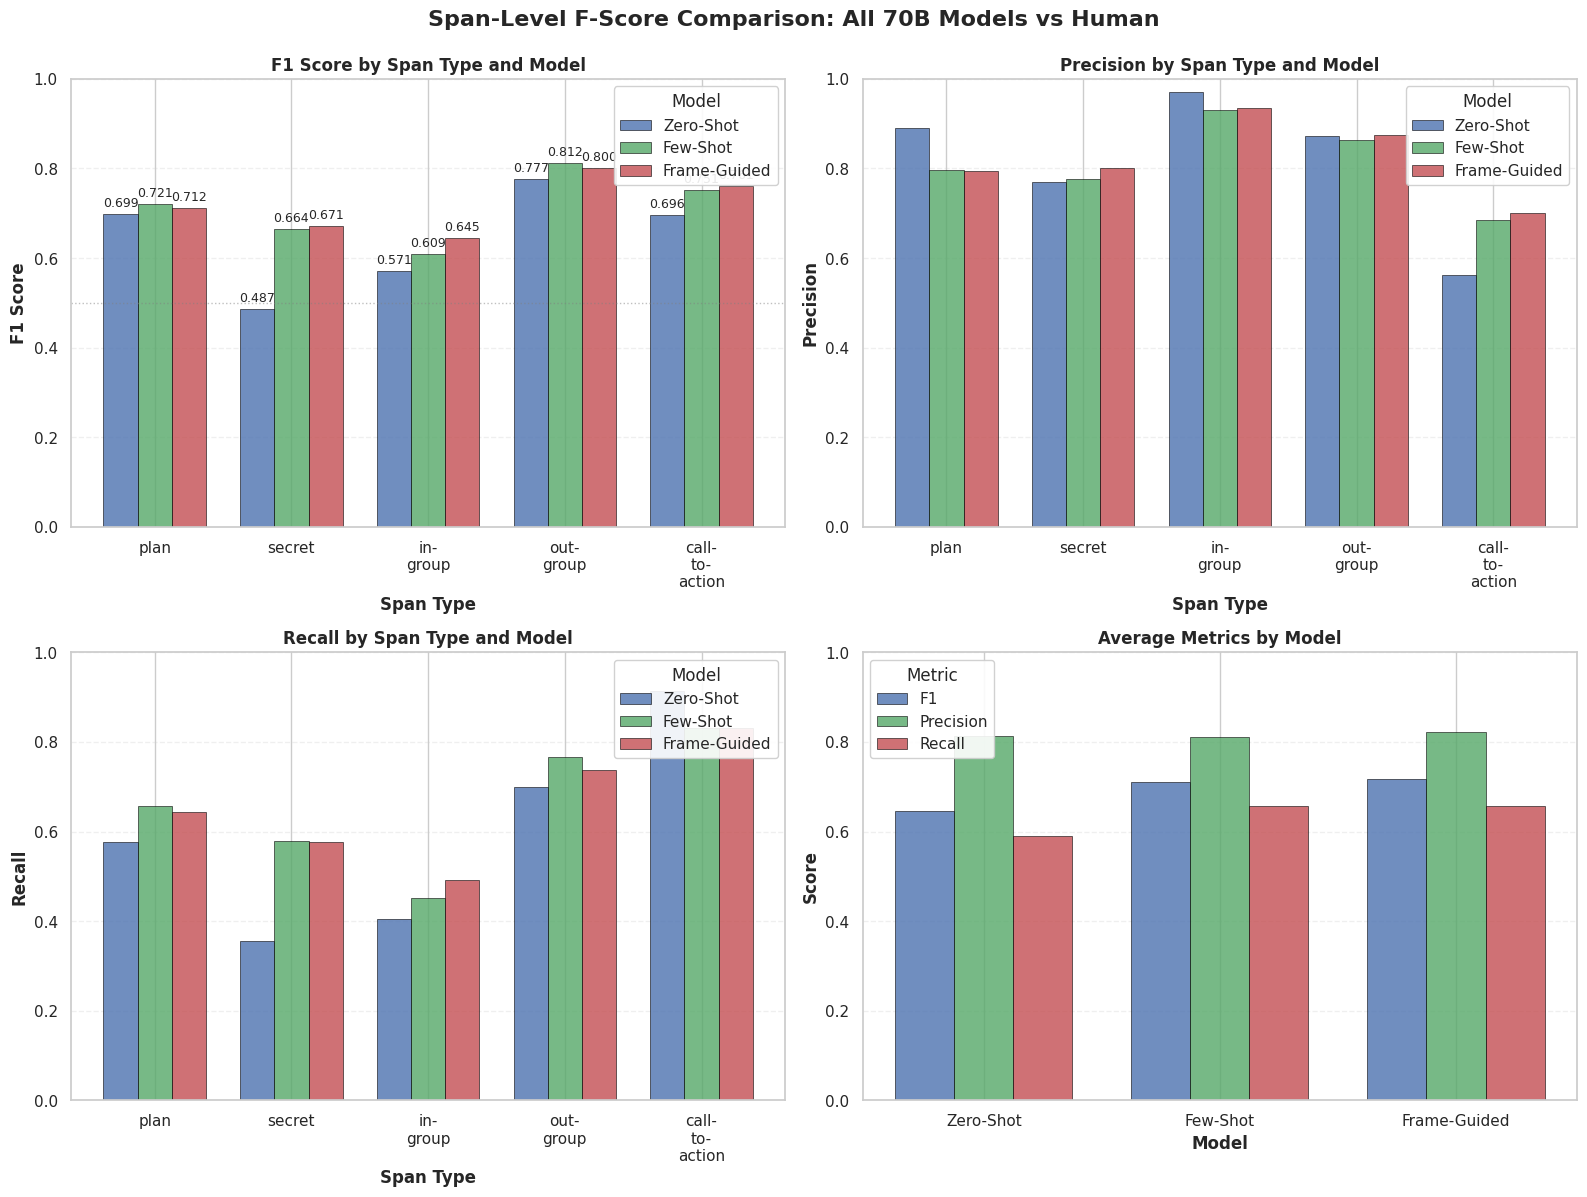

In [7]:
# Create visualizations
import matplotlib.pyplot as plt
import seaborn as sns

# Set style
sns.set_theme(context="notebook", style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (14, 8)
plt.rcParams['font.size'] = 11

# Create figure with subplots
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Span-Level F-Score Comparison: All 70B Models vs Human', fontsize=16, fontweight='bold', y=0.995)

# 1. F1 Score Comparison (Main plot - larger)
ax1 = axes[0, 0]
x_pos = np.arange(len(DESIRED_ORDER))
width = 0.25

# Get F1 values for each model
models_in_order = list(MODELS.keys())
colors = ['#4C72B0', '#55A868', '#C44E52']  # Blue, Green, Red

for i, model_name in enumerate(models_in_order):
    if model_name not in all_metrics_sorted['Model'].values:
        continue
    f1_values = []
    for span_type in DESIRED_ORDER:
        row_data = all_metrics_sorted[
            (all_metrics_sorted['Model'] == model_name) & 
            (all_metrics_sorted['Span_Type'] == span_type)
        ]
        if len(row_data) > 0:
            f1_values.append(row_data.iloc[0]['F1'])
        else:
            f1_values.append(0)
    
    offset = (i - 1) * width
    # Create display label: remove '70B ' prefix and replace 'Few-Shot+Frames' with 'Frame-Guided'
    display_label = model_name.replace('70B ', '').replace('Few-Shot+Frames', 'Frame-Guided')
    bars = ax1.bar(x_pos + offset, f1_values, width, label=display_label, 
                   color=colors[i % len(colors)], alpha=0.8, edgecolor='black', linewidth=0.5)
    
    # Add value labels on bars
    for bar in bars:
        height = bar.get_height()
        if height > 0:
            ax1.text(bar.get_x() + bar.get_width()/2., height + 0.01,
                    f'{height:.3f}', ha='center', va='bottom', fontsize=9)

ax1.set_xlabel('Span Type', fontweight='bold')
ax1.set_ylabel('F1 Score', fontweight='bold')
ax1.set_title('F1 Score by Span Type and Model', fontweight='bold')
ax1.set_xticks(x_pos)
ax1.set_xticklabels([s.replace('-', '-\n') for s in DESIRED_ORDER], rotation=0, ha='center')
ax1.set_ylim(0, 1.0)
ax1.legend(title='Model', loc='upper right', framealpha=0.9)
ax1.grid(axis='y', alpha=0.3, linestyle='--')
ax1.axhline(y=0.5, color='gray', linestyle=':', linewidth=1, alpha=0.5)

# 2. Precision Comparison
ax2 = axes[0, 1]
for i, model_name in enumerate(models_in_order):
    if model_name not in all_metrics_sorted['Model'].values:
        continue
    precision_values = []
    for span_type in DESIRED_ORDER:
        row_data = all_metrics_sorted[
            (all_metrics_sorted['Model'] == model_name) & 
            (all_metrics_sorted['Span_Type'] == span_type)
        ]
        if len(row_data) > 0:
            precision_values.append(row_data.iloc[0]['Precision'])
        else:
            precision_values.append(0)
    
    offset = (i - 1) * width
    # Create display label: remove '70B ' prefix and replace 'Few-Shot+Frames' with 'Frame-Guided'
    display_label = model_name.replace('70B ', '').replace('Few-Shot+Frames', 'Frame-Guided')
    ax2.bar(x_pos + offset, precision_values, width, label=display_label,
           color=colors[i % len(colors)], alpha=0.8, edgecolor='black', linewidth=0.5)

ax2.set_xlabel('Span Type', fontweight='bold')
ax2.set_ylabel('Precision', fontweight='bold')
ax2.set_title('Precision by Span Type and Model', fontweight='bold')
ax2.set_xticks(x_pos)
ax2.set_xticklabels([s.replace('-', '-\n') for s in DESIRED_ORDER], rotation=0, ha='center')
ax2.set_ylim(0, 1.0)
ax2.legend(title='Model', loc='upper right', framealpha=0.9)
ax2.grid(axis='y', alpha=0.3, linestyle='--')

# 3. Recall Comparison
ax3 = axes[1, 0]
for i, model_name in enumerate(models_in_order):
    if model_name not in all_metrics_sorted['Model'].values:
        continue
    recall_values = []
    for span_type in DESIRED_ORDER:
        row_data = all_metrics_sorted[
            (all_metrics_sorted['Model'] == model_name) & 
            (all_metrics_sorted['Span_Type'] == span_type)
        ]
        if len(row_data) > 0:
            recall_values.append(row_data.iloc[0]['Recall'])
        else:
            recall_values.append(0)
    
    offset = (i - 1) * width
    # Create display label: remove '70B ' prefix and replace 'Few-Shot+Frames' with 'Frame-Guided'
    display_label = model_name.replace('70B ', '').replace('Few-Shot+Frames', 'Frame-Guided')
    ax3.bar(x_pos + offset, recall_values, width, label=display_label,
           color=colors[i % len(colors)], alpha=0.8, edgecolor='black', linewidth=0.5)

ax3.set_xlabel('Span Type', fontweight='bold')
ax3.set_ylabel('Recall', fontweight='bold')
ax3.set_title('Recall by Span Type and Model', fontweight='bold')
ax3.set_xticks(x_pos)
ax3.set_xticklabels([s.replace('-', '-\n') for s in DESIRED_ORDER], rotation=0, ha='center')
ax3.set_ylim(0, 1.0)
ax3.legend(title='Model', loc='upper right', framealpha=0.9)
ax3.grid(axis='y', alpha=0.3, linestyle='--')

# 4. Average Metrics by Model
ax4 = axes[1, 1]
model_avgs = {}
for model_name in models_in_order:
    if model_name not in all_metrics_sorted['Model'].values:
        continue
    model_data = all_metrics_sorted[all_metrics_sorted['Model'] == model_name]
    model_avgs[model_name] = {
        'F1': model_data['F1'].mean(),
        'Precision': model_data['Precision'].mean(),
        'Recall': model_data['Recall'].mean()
    }

x_model = np.arange(len(model_avgs))
metrics_to_plot = ['F1', 'Precision', 'Recall']
colors_metrics = ['#4C72B0', '#55A868', '#C44E52']

for i, metric in enumerate(metrics_to_plot):
    values = [model_avgs[model][metric] for model in model_avgs.keys()]
    ax4.bar(x_model + (i - 1) * width, values, width, label=metric,
           color=colors_metrics[i], alpha=0.8, edgecolor='black', linewidth=0.5)

ax4.set_xlabel('Model', fontweight='bold')
ax4.set_ylabel('Score', fontweight='bold')
ax4.set_title('Average Metrics by Model', fontweight='bold')
ax4.set_xticks(x_model)
ax4.set_xticklabels([m.replace('70B ', '').replace('Few-Shot+Frames', 'Frame-Guided') for m in model_avgs.keys()], rotation=0, ha='center')
ax4.set_ylim(0, 1.0)
ax4.legend(title='Metric', loc='upper left', framealpha=0.9)
ax4.grid(axis='y', alpha=0.3, linestyle='--')

plt.tight_layout()

# Save figure
PUB_FIGURES = BASE / 'publication' / 'figures'
PUB_FIGURES.mkdir(exist_ok=True, parents=True)
fig_path = PUB_FIGURES / 'span_fscore_all_70b_comparison.png'
plt.savefig(fig_path, dpi=300, bbox_inches='tight', facecolor='white')
print(f"✓ Saved visualization: {fig_path}")

plt.show()


### Alternative: Single F1 Comparison Plot (for paper)


✓ Saved single F1 comparison plot: /home/ashrafs/projects/Conspiracy-Proj/publication/figures/span_fscore_all_70b_f1_comparison.png


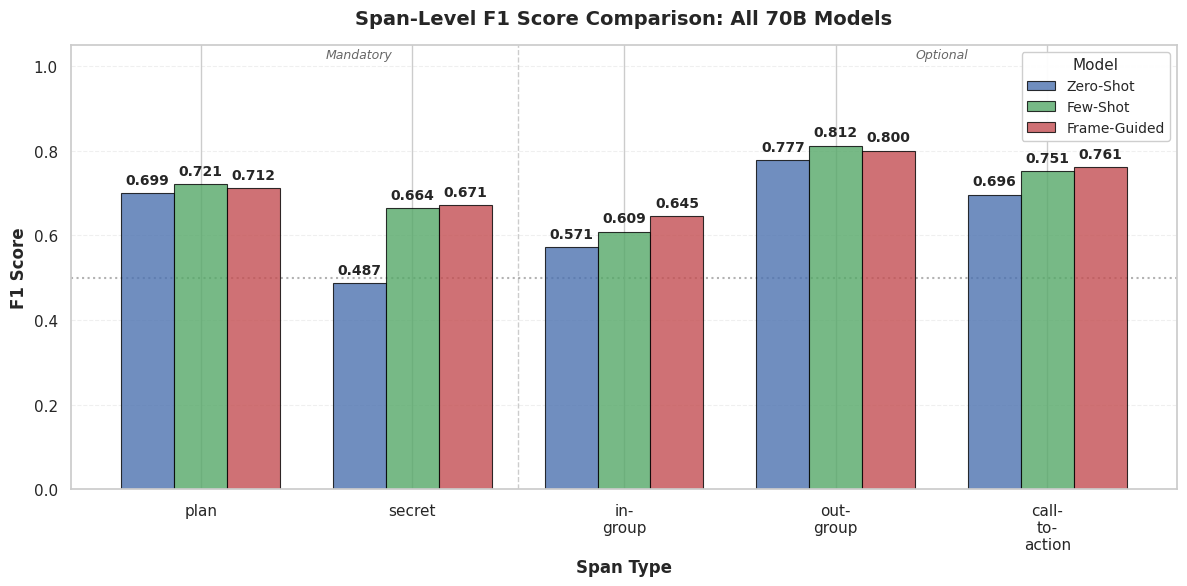

In [8]:
# Create a cleaner single plot focused on F1 scores (better for paper)
fig2, ax2 = plt.subplots(1, 1, figsize=(12, 6))

x_pos = np.arange(len(DESIRED_ORDER))
width = 0.25
models_in_order = list(MODELS.keys())
colors = ['#4C72B0', '#55A868', '#C44E52']  # Blue, Green, Red

for i, model_name in enumerate(models_in_order):
    if model_name not in all_metrics_sorted['Model'].values:
        continue
    f1_values = []
    for span_type in DESIRED_ORDER:
        row_data = all_metrics_sorted[
            (all_metrics_sorted['Model'] == model_name) & 
            (all_metrics_sorted['Span_Type'] == span_type)
        ]
        if len(row_data) > 0:
            f1_values.append(row_data.iloc[0]['F1'])
        else:
            f1_values.append(0)
    
    offset = (i - 1) * width
    # Create display label: remove '70B ' prefix and replace 'Few-Shot+Frames' with 'Frame-Guided'
    display_label = model_name.replace('70B ', '').replace('Few-Shot+Frames', 'Frame-Guided')
    bars = ax2.bar(x_pos + offset, f1_values, width, label=display_label, 
                   color=colors[i % len(colors)], alpha=0.8, edgecolor='black', linewidth=0.8)
    
    # Add value labels on bars
    for j, bar in enumerate(bars):
        height = bar.get_height()
        if height > 0:
            ax2.text(bar.get_x() + bar.get_width()/2., height + 0.015,
                    f'{height:.3f}', ha='center', va='bottom', fontsize=10, fontweight='bold')

ax2.set_xlabel('Span Type', fontweight='bold', fontsize=12)
ax2.set_ylabel('F1 Score', fontweight='bold', fontsize=12)
ax2.set_title('Span-Level F1 Score Comparison: All 70B Models', fontweight='bold', fontsize=14, pad=15)
ax2.set_xticks(x_pos)
# Better formatting for span type labels
span_labels = [s.replace('-', '-\n') if '-' in s else s for s in DESIRED_ORDER]
ax2.set_xticklabels(span_labels, rotation=0, ha='center', fontsize=11)
ax2.set_ylim(0, 1.05)
ax2.legend(title='Model', loc='upper right', framealpha=0.95, fontsize=10, title_fontsize=11)
ax2.grid(axis='y', alpha=0.3, linestyle='--', linewidth=0.8)
ax2.axhline(y=0.5, color='gray', linestyle=':', linewidth=1.5, alpha=0.6, zorder=0)

# Add vertical line to separate mandatory from optional
ax2.axvline(x=1.5, color='gray', linestyle='--', linewidth=1, alpha=0.4)
ax2.text(0.75, 1.02, 'Mandatory', ha='center', fontsize=9, style='italic', alpha=0.7)
ax2.text(3.5, 1.02, 'Optional', ha='center', fontsize=9, style='italic', alpha=0.7)

plt.tight_layout()

# Save figure
fig_path_single = PUB_FIGURES / 'span_fscore_all_70b_f1_comparison.png'
plt.savefig(fig_path_single, dpi=300, bbox_inches='tight', facecolor='white')
print(f"✓ Saved single F1 comparison plot: {fig_path_single}")

plt.show()


## 7. Export Results


## 6. Export Results


In [9]:
# Export as CSV
if len(all_metrics_df) > 0:
    csv_path = PUB_TABLES / 'span_fscore_all_70b_models.csv'
    all_metrics_sorted[['Model', 'Span_Type', 'Precision', 'Recall', 'F1', 'N_Human_Spans', 'N_Model_Spans', 'N_Matched']].to_csv(
        csv_path, index=False, float_format='%.4f'
    )
    print(f"✓ Exported CSV: {csv_path}")
    
    # Export as LaTeX table (wide format - models as columns)
    latex_path = PUB_TABLES / 'span_fscore_all_70b_models.tex'
    
    latex_str = "\\begin{table*}[t]\n"
    latex_str += "\\centering\n"
    latex_str += "\\caption{Span-Level F-Score Analysis: All 70B Models vs Human Annotations}\n"
    latex_str += "\\label{tab:span_fscore_all_70b}\n"
    latex_str += "\\begin{tabular}{l" + "ccc" * len(MODELS) + "}\n"  # l for span type, then 3 cols (P, R, F1) per model
    latex_str += "\\toprule\n"
    
    # Header row 1: Model names
    latex_str += "Span Type"
    for model_name in MODELS.keys():
        if model_name in all_metrics_sorted['Model'].values:
            # Shorten model names for header
            model_short = model_name.replace('70B ', '').replace('+', '+')
            latex_str += f" & \\multicolumn{{3}}{{c}}{{{model_short}}}"
    latex_str += " \\\\\n"
    
    # Header row 2: Metrics
    latex_str += " & "
    for model_name in MODELS.keys():
        if model_name in all_metrics_sorted['Model'].values:
            latex_str += "P & R & F1 &"
    latex_str = latex_str.rstrip(' &') + " \\\\\n"
    latex_str += "\\midrule\n"
    
    # Data rows: one per span type
    for span_type in DESIRED_ORDER:
        if span_type not in all_metrics_sorted['Span_Type'].values:
            continue
        
        span_display = span_type.replace('-', '\\textendash ')
        latex_str += f"{span_display}"
        
        for model_name in MODELS.keys():
            if model_name not in all_metrics_sorted['Model'].values:
                continue
            
            row_data = all_metrics_sorted[
                (all_metrics_sorted['Model'] == model_name) & 
                (all_metrics_sorted['Span_Type'] == span_type)
            ]
            
            if len(row_data) > 0:
                p = row_data.iloc[0]['Precision']
                r = row_data.iloc[0]['Recall']
                f1 = row_data.iloc[0]['F1']
                latex_str += f" & {p:.4f} & {r:.4f} & {f1:.4f}"
            else:
                latex_str += " & -- & -- & --"
        
        latex_str += " \\\\\n"
    
    latex_str += "\\bottomrule\n"
    latex_str += "\\end{tabular}\n"
    latex_str += "\\end{table*}\n"
    
    with open(latex_path, 'w') as f:
        f.write(latex_str)
    
    print(f"✓ Exported LaTeX table: {latex_path}")
    
    print("\n" + "=" * 80)
    print("Export Summary:")
    print(f"  - CSV: {csv_path}")
    print(f"  - LaTeX: {latex_path}")
    print("=" * 80)
else:
    print("No span metrics to export.")


✓ Exported CSV: /home/ashrafs/projects/Conspiracy-Proj/publication/tables/span_fscore_all_70b_models.csv
✓ Exported LaTeX table: /home/ashrafs/projects/Conspiracy-Proj/publication/tables/span_fscore_all_70b_models.tex

Export Summary:
  - CSV: /home/ashrafs/projects/Conspiracy-Proj/publication/tables/span_fscore_all_70b_models.csv
  - LaTeX: /home/ashrafs/projects/Conspiracy-Proj/publication/tables/span_fscore_all_70b_models.tex
